# 03 - Análisis por Sistema y Modelo: Kruskal-Wallis + Dunn

## Objetivo
- Comparar métricas entre sistemas de recuperación (Kruskal-Wallis + Dunn post-hoc)
- Comparar métricas entre modelos
- Comparar modelos dentro de cada sistema de recuperación (estratificado)

## Tests
- **Kruskal-Wallis**: test no paramétrico para comparar 3+ grupos independientes
- **Dunn con corrección de Bonferroni**: post-hoc para identificar qué pares difieren

In [1]:
import json
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import scikit_posthocs as sp
from pathlib import Path

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 8)})

DATA_DIR = Path("..") / "part_i"

In [2]:
df = pl.read_csv(DATA_DIR / "combined_metrics_for_analysis.csv")
print(f"Datos: {df.shape}")

# Cargar VR seleccionadas desde el archivo compartido
with open("vr_seleccionadas.json", "r", encoding="utf-8") as f:
    vr_config = json.load(f)

VR_SELECCIONADAS = vr_config["vr_seleccionadas"]

ESTRATEGIAS = sorted(df["estrategia"].unique().to_list())
MODELOS = sorted(df["id_modelo_especialista"].unique().to_list())

print(f"\nVR seleccionadas ({len(VR_SELECCIONADAS)}): {VR_SELECCIONADAS}")
print(f"Estrategias: {ESTRATEGIAS}")
print(f"Modelos: {MODELOS}")

Datos: (711, 22)

VR seleccionadas (1): ['respuesta_correcta_avg']
Estrategias: ['llm_responses_agentic_rag', 'llm_responses_base_rag', 'llm_responses_no_rag']
Modelos: ['gpt-5', 'gpt-5-mini', 'gpt-5-nano']


## 1. ¿El sistema de recuperación mejora la calidad de las respuestas?

VI: sistema de recuperación (3 niveles)
VR: métricas seleccionadas

### 1.1 Kruskal-Wallis por métrica

In [3]:
kw_sistema_results = []

for metrica in VR_SELECCIONADAS:
    groups = []
    for est in ESTRATEGIAS:
        data = df.filter(pl.col("estrategia") == est)[metrica].drop_nulls().to_numpy()
        groups.append(data)

    if all(len(g) > 0 for g in groups):
        h_stat, p_val = stats.kruskal(*groups)
        kw_sistema_results.append({
            "metrica": metrica,
            "H_statistic": round(h_stat, 4),
            "p_value": p_val,
            "significativo_005": p_val < 0.05,
            "significativo_001": p_val < 0.01,
        })

df_kw_sistema = pl.DataFrame(kw_sistema_results).sort("p_value")
print("Kruskal-Wallis: Efecto del sistema de recuperación")
display(df_kw_sistema)

Kruskal-Wallis: Efecto del sistema de recuperación


metrica,H_statistic,p_value,significativo_005,significativo_001
str,f64,f64,i64,i64
"""respuesta_correcta_avg""",21.8257,0.000018,1,1


### 1.2 Post-hoc de Dunn (corrección Bonferroni) por sistema

In [4]:
for metrica in VR_SELECCIONADAS:
    records = []
    for est in ESTRATEGIAS:
        vals = df.filter(pl.col("estrategia") == est)[metrica].drop_nulls().to_list()
        for v in vals:
            records.append({"estrategia": est.replace("llm_responses_", ""), "valor": v})

    df_pd = pd.DataFrame(records)

    if len(df_pd) > 0:
        dunn_result = sp.posthoc_dunn(
            df_pd, val_col="valor", group_col="estrategia", p_adjust="bonferroni"
        )
        print(f"\n{'='*60}")
        print(f"Dunn post-hoc (Bonferroni) - {metrica}")
        print(f"{'='*60}")
        display(dunn_result)


Dunn post-hoc (Bonferroni) - respuesta_correcta_avg


,agentic_rag,base_rag,no_rag
agentic_rag,1.000000,0.382889,0.000014
base_rag,0.382889,1.000000,0.006575
no_rag,0.000014,0.006575,1.000000


### 1.3 Visualización: boxplots por sistema

/tmp/ipykernel_163220/730787309.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_strat, labels=labels_cortas, patch_artist=True)


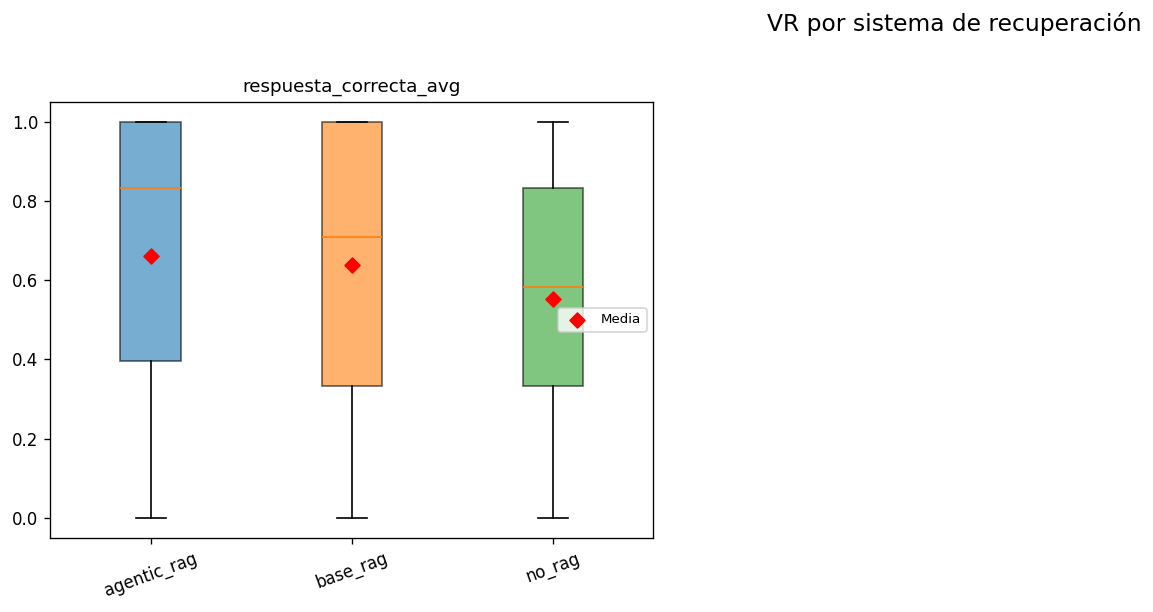

In [5]:
n_metrics = len(VR_SELECCIONADAS)
n_cols = 3
n_rows = (n_metrics + n_cols - 1) // n_cols

colores = ["#1f77b4", "#ff7f0e", "#2ca02c"]
labels_cortas = [e.replace("llm_responses_", "") for e in ESTRATEGIAS]

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

for i, metrica in enumerate(VR_SELECCIONADAS):
    ax = axes[i]
    data_by_strat = []
    for est in ESTRATEGIAS:
        vals = df.filter(pl.col("estrategia") == est)[metrica].drop_nulls().to_numpy()
        data_by_strat.append(vals)

    bp = ax.boxplot(data_by_strat, labels=labels_cortas, patch_artist=True)
    for patch, color in zip(bp["boxes"], colores):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    # Agregar medias
    means = [d.mean() for d in data_by_strat]
    ax.scatter(range(1, len(means) + 1), means, color="red", marker="D", s=40, zorder=5, label="Media")

    ax.set_title(metrica, fontsize=11)
    ax.tick_params(axis="x", rotation=20)
    if i == 0:
        ax.legend(fontsize=8)

for j in range(n_metrics, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("VR por sistema de recuperación", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 2. ¿Hay diferencia entre el desempeño de los modelos?

VI: modelo (3 niveles: gpt-5-nano, gpt-5-mini, gpt-5)

### 2.1 Kruskal-Wallis por métrica

In [6]:
kw_modelo_results = []

for metrica in VR_SELECCIONADAS:
    groups = []
    for modelo in MODELOS:
        data = df.filter(pl.col("id_modelo_especialista") == modelo)[metrica].drop_nulls().to_numpy()
        groups.append(data)

    if all(len(g) > 0 for g in groups):
        h_stat, p_val = stats.kruskal(*groups)
        kw_modelo_results.append({
            "metrica": metrica,
            "H_statistic": round(h_stat, 4),
            "p_value": p_val,
            "significativo_005": p_val < 0.05,
            "significativo_001": p_val < 0.01,
        })

df_kw_modelo = pl.DataFrame(kw_modelo_results).sort("p_value")
print("Kruskal-Wallis: Efecto del modelo")
display(df_kw_modelo)

Kruskal-Wallis: Efecto del modelo


metrica,H_statistic,p_value,significativo_005,significativo_001
str,f64,f64,i64,i64
"""respuesta_correcta_avg""",49.0121,2.2759e-11,1,1


### 2.2 Post-hoc de Dunn por modelo

In [7]:
for metrica in VR_SELECCIONADAS:
    records = []
    for modelo in MODELOS:
        vals = df.filter(pl.col("id_modelo_especialista") == modelo)[metrica].drop_nulls().to_list()
        for v in vals:
            records.append({"modelo": modelo, "valor": v})

    df_pd = pd.DataFrame(records)

    if len(df_pd) > 0:
        dunn_result = sp.posthoc_dunn(
            df_pd, val_col="valor", group_col="modelo", p_adjust="bonferroni"
        )
        print(f"\n{'='*60}")
        print(f"Dunn post-hoc (Bonferroni) - {metrica}")
        print(f"{'='*60}")
        display(dunn_result)


Dunn post-hoc (Bonferroni) - respuesta_correcta_avg


,gpt-5,gpt-5-mini,gpt-5-nano
gpt-5,1.000000e+00,0.000007,2.389451e-11
gpt-5-mini,7.247993e-06,1.000000,1.009890e-01
gpt-5-nano,2.389451e-11,0.100989,1.000000e+00


### 2.3 Visualización: boxplots por modelo

/tmp/ipykernel_163220/1210298577.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_model, labels=MODELOS, patch_artist=True)


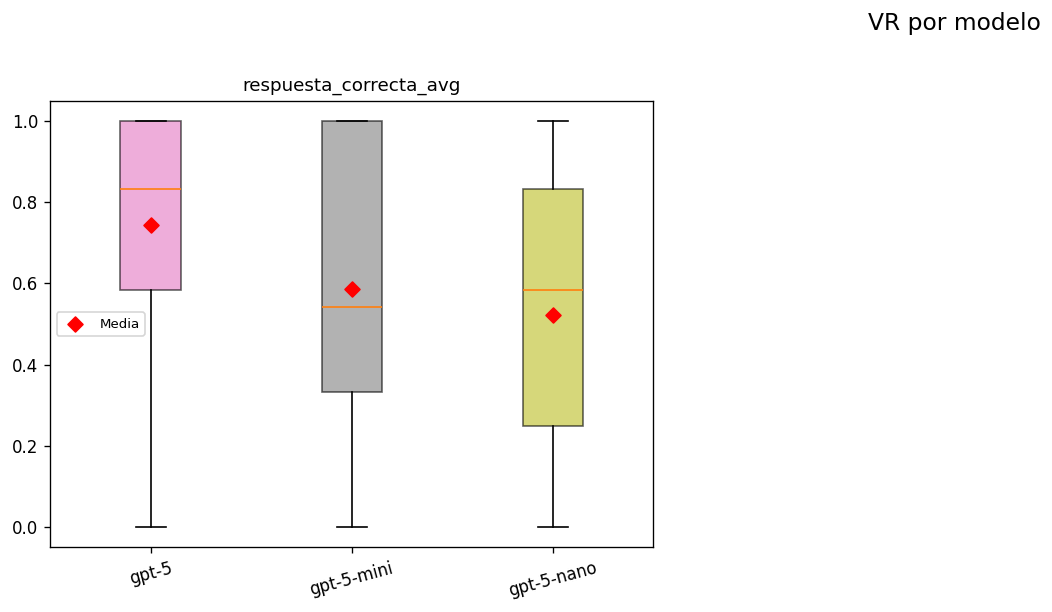

In [8]:
colores_modelo = ["#e377c2", "#7f7f7f", "#bcbd22"]

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

for i, metrica in enumerate(VR_SELECCIONADAS):
    ax = axes[i]
    data_by_model = []
    for modelo in MODELOS:
        vals = df.filter(pl.col("id_modelo_especialista") == modelo)[metrica].drop_nulls().to_numpy()
        data_by_model.append(vals)

    bp = ax.boxplot(data_by_model, labels=MODELOS, patch_artist=True)
    for patch, color in zip(bp["boxes"], colores_modelo):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    means = [d.mean() for d in data_by_model]
    ax.scatter(range(1, len(means) + 1), means, color="red", marker="D", s=40, zorder=5, label="Media")
    ax.set_title(metrica, fontsize=11)
    ax.tick_params(axis="x", rotation=15)
    if i == 0:
        ax.legend(fontsize=8)

for j in range(n_metrics, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("VR por modelo", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 3. Comparación de modelos estratificada por sistema

Para cada sistema de recuperación, ¿hay diferencia entre modelos?

**Nota**: Se aplica corrección de Bonferroni al nivel de significancia por las múltiples comparaciones (3 sistemas × N métricas seleccionadas).

In [9]:
N_TESTS = len(ESTRATEGIAS) * len(VR_SELECCIONADAS)
ALPHA_CORREGIDO = 0.05 / N_TESTS
print(f"Número de tests: {N_TESTS}")
print(f"Alpha corregido (Bonferroni): {ALPHA_CORREGIDO:.6f}")

kw_strat_results = []

for estrategia in ESTRATEGIAS:
    df_est = df.filter(pl.col("estrategia") == estrategia)

    for metrica in VR_SELECCIONADAS:
        groups = []
        for modelo in MODELOS:
            data = df_est.filter(pl.col("id_modelo_especialista") == modelo)[metrica].drop_nulls().to_numpy()
            groups.append(data)

        if all(len(g) > 0 for g in groups):
            h_stat, p_val = stats.kruskal(*groups)
            kw_strat_results.append({
                "estrategia": estrategia.replace("llm_responses_", ""),
                "metrica": metrica,
                "H_statistic": round(h_stat, 4),
                "p_value": p_val,
                "sig_005": p_val < 0.05,
                "sig_bonferroni": p_val < ALPHA_CORREGIDO,
            })

df_kw_strat = pl.DataFrame(kw_strat_results).sort("estrategia", "p_value")
display(df_kw_strat)

Número de tests: 3
Alpha corregido (Bonferroni): 0.016667


estrategia,metrica,H_statistic,p_value,sig_005,sig_bonferroni
str,str,f64,f64,i64,i64
"""agentic_rag""","""respuesta_correcta_avg""",40.6376,1.4985e-9,1,1
"""base_rag""","""respuesta_correcta_avg""",4.7066,0.095056,0,0
"""no_rag""","""respuesta_correcta_avg""",59.6669,1.1053e-13,1,1


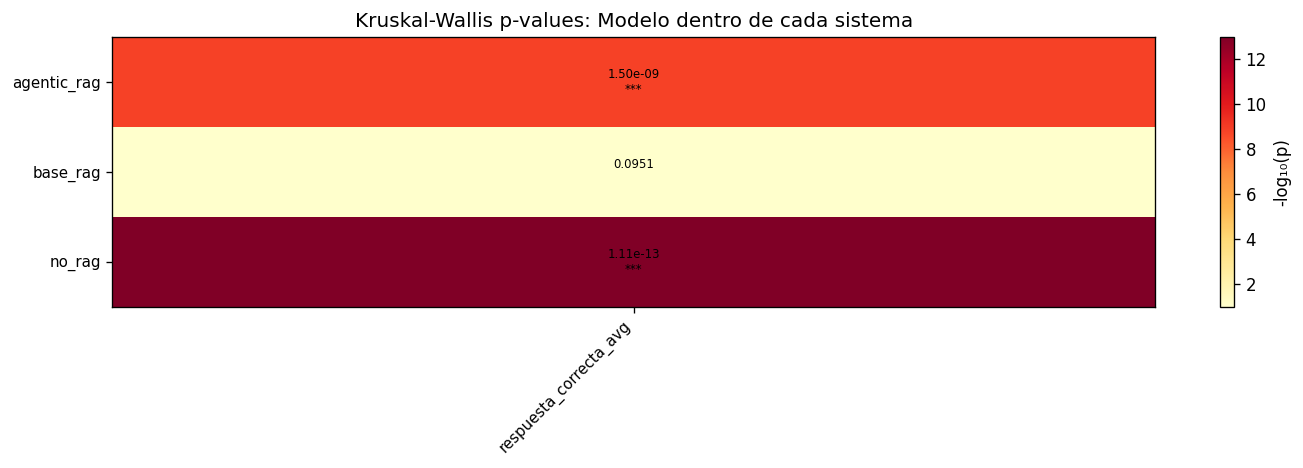

In [10]:
# Heatmap resumen: significancia por estrategia × métrica
pivot_sig = df_kw_strat.pivot(
    on="metrica", index="estrategia", values="p_value"
)

estrategias_order = sorted(pivot_sig["estrategia"].to_list())
metricas_order = VR_SELECCIONADAS

matrix = np.zeros((len(estrategias_order), len(metricas_order)))
for i, est in enumerate(estrategias_order):
    row = pivot_sig.filter(pl.col("estrategia") == est)
    for j, met in enumerate(metricas_order):
        if met in row.columns:
            val = row[met][0]
            matrix[i, j] = val if val is not None else 1.0
        else:
            matrix[i, j] = 1.0

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(-np.log10(matrix + 1e-300), cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(metricas_order)))
ax.set_yticks(range(len(estrategias_order)))
ax.set_xticklabels(metricas_order, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(estrategias_order, fontsize=9)

for i in range(len(estrategias_order)):
    for j in range(len(metricas_order)):
        p = matrix[i, j]
        label = f"{p:.4f}" if p >= 0.0001 else f"{p:.2e}"
        sig = "*" if p < 0.05 else ""
        sig += "*" if p < 0.01 else ""
        sig += "*" if p < 0.001 else ""
        ax.text(j, i, f"{label}\n{sig}", ha="center", va="center", fontsize=7)

plt.colorbar(im, ax=ax, label="-log₁₀(p)")
ax.set_title("Kruskal-Wallis p-values: Modelo dentro de cada sistema")
plt.tight_layout()
plt.show()

## 4. Resumen

In [11]:
print("="*60)
print("RESUMEN DE RESULTADOS")
print("="*60)

print("\n--- Efecto del sistema de recuperación ---")
for row in df_kw_sistema.iter_rows(named=True):
    sig = "SÍ" if row["significativo_005"] else "NO"
    print(f"  {row['metrica']}: H={row['H_statistic']:.4f}, p={row['p_value']:.6f} → Significativo: {sig}")

print("\n--- Efecto del modelo ---")
for row in df_kw_modelo.iter_rows(named=True):
    sig = "SÍ" if row["significativo_005"] else "NO"
    print(f"  {row['metrica']}: H={row['H_statistic']:.4f}, p={row['p_value']:.6f} → Significativo: {sig}")

print("\n--- Modelo dentro de cada sistema (Bonferroni) ---")
for row in df_kw_strat.iter_rows(named=True):
    sig = "SÍ" if row["sig_bonferroni"] else "NO"
    print(f"  [{row['estrategia']}] {row['metrica']}: p={row['p_value']:.6f} → Sig (Bonf): {sig}")

RESUMEN DE RESULTADOS

--- Efecto del sistema de recuperación ---
  respuesta_correcta_avg: H=21.8257, p=0.000018 → Significativo: SÍ

--- Efecto del modelo ---
  respuesta_correcta_avg: H=49.0121, p=0.000000 → Significativo: SÍ

--- Modelo dentro de cada sistema (Bonferroni) ---
  [agentic_rag] respuesta_correcta_avg: p=0.000000 → Sig (Bonf): SÍ
  [base_rag] respuesta_correcta_avg: p=0.095056 → Sig (Bonf): NO
  [no_rag] respuesta_correcta_avg: p=0.000000 → Sig (Bonf): SÍ


## 5. Conclusión Final

### 5.1 Efecto del sistema de recuperación

El test de Kruskal-Wallis reveló diferencias estadísticamente significativas entre los tres sistemas de recuperación para la métrica `respuesta_correcta_avg` (H = 21.83, p < 0.001). El análisis post-hoc de Dunn con corrección de Bonferroni permitió identificar dónde se encuentran esas diferencias:

| Comparación | p-valor (Bonferroni) | Significativo (α=0.05) |
|---|---|---|
| agentic_rag vs. no_rag | 0.000014 | **Sí** |
| base_rag vs. no_rag | 0.0066 | **Sí** |
| agentic_rag vs. base_rag | 0.383 | No |

**Interpretación**: Ambos sistemas RAG (agentic y base) superan significativamente al escenario sin RAG. Sin embargo, **no se detectó una diferencia significativa entre agentic_rag y base_rag**, lo que sugiere que el componente agéntico no aporta una mejora estadísticamente distinguible sobre el RAG base en esta métrica. Las medianas observadas fueron: agentic_rag = 0.8333, base_rag = 0.7083, no_rag = 0.5833.

### 5.2 Efecto del modelo

El test de Kruskal-Wallis mostró diferencias altamente significativas entre los modelos (H = 49.01, p < 0.001). El post-hoc de Dunn reveló:

| Comparación | p-valor (Bonferroni) | Significativo (α=0.05) |
|---|---|---|
| gpt-5 vs. gpt-5-nano | < 0.0001 | **Sí** |
| gpt-5 vs. gpt-5-mini | 0.000007 | **Sí** |
| gpt-5-mini vs. gpt-5-nano | 0.101 | No |

**Interpretación**: El modelo gpt-5 se diferencia significativamente de gpt-5-mini y gpt-5-nano, con una mediana de 0.8333 frente a 0.5417 y 0.5833 respectivamente. Los modelos más pequeños (mini y nano) **no presentan diferencias significativas entre sí**, lo que indica que la ganancia en calidad de respuesta se concentra en el salto hacia el modelo de mayor capacidad.

### 5.3 Interacción: modelo dentro de cada sistema (análisis estratificado)

El análisis estratificado (con corrección de Bonferroni por múltiples comparaciones, α corregido = 0.0167) reveló un hallazgo particularmente relevante:

| Sistema | H | p-valor | Sig. (Bonferroni) |
|---|---|---|---|
| agentic_rag | 40.64 | < 0.0001 | **Sí** |
| no_rag | 59.67 | < 0.0001 | **Sí** |
| base_rag | 4.71 | 0.095 | No |

**Interpretación**: La elección del modelo importa significativamente cuando se usa agentic_rag o no se usa RAG, pero **no importa significativamente dentro del sistema base_rag**. Este resultado es notable porque sugiere que el sistema base_rag tiene un efecto ecualizador sobre el rendimiento de los distintos modelos: independientemente de la capacidad del modelo, el RAG base tiende a producir resultados comparables.

### 5.4 Observaciones generales

1. **El RAG mejora la calidad de las respuestas**: Tanto base_rag como agentic_rag generan respuestas significativamente superiores al escenario sin RAG, confirmando la utilidad de la recuperación de información como estrategia de mejora.

2. **El modelo de mayor capacidad (gpt-5) domina en calidad general**: Con una mediana de 0.8333, gpt-5 supera consistentemente a los modelos más pequeños, lo cual es esperable dado su mayor capacidad de razonamiento.

3. **El RAG base como ecualizador**: El hallazgo de que base_rag elimina las diferencias significativas entre modelos es de interés práctico: si se dispone de un sistema RAG base adecuado, podría ser viable utilizar un modelo más económico (gpt-5-mini o gpt-5-nano) sin sacrificar significativamente la calidad de las respuestas.

4. **Limitación de la métrica única**: Este análisis se basó en una sola variable respuesta (`respuesta_correcta_avg`). Sería recomendable complementar estos hallazgos con análisis sobre métricas adicionales (por ejemplo, completitud, coherencia, u otras dimensiones de calidad) para obtener un panorama más completo de las diferencias entre sistemas y modelos.

5. **Consideraciones sobre el test**: Se utilizó Kruskal-Wallis por tratarse de datos que no necesariamente cumplen los supuestos de normalidad y homocedasticidad requeridos por ANOVA. La corrección de Bonferroni en los post-hoc y en el análisis estratificado asegura el control del error de Tipo I ante las múltiples comparaciones realizadas.